# MPRA Pleiotropy: Analysis of discordant allelic MPRA effects in HepG2 (IGVFFI4134MFLL) vs HEK293T (IGVFFI4378PZYI)

In [77]:
import requests
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import cohen_kappa_score
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredText

In [78]:
def paginated(url, page_size=25, max_results=1000, verbose=False):
    ''' This is a utility function to page results from the Catalog API
        use page_size (default = 25 records) and max_results (default=1000 records)
        One query is made per page, up to max_results.
    '''

    page = 0
    found = 'start'
    data = []
    total_found = 0
    request_url = url + "&page=%s&limit=%s" % (page, page_size)
    while(found and len(data) <= max_results):
        if found == 'start':
            found = 0
        res = requests.get(url+ "&page=%s&limit=%s" % (page, page_size)  )
        if res.status_code == 200:
            found = len(res.json())
            total_found = total_found + found
            if verbose:
                print("url: %s page: %s found: %s total: %s" % (request_url, page, found, total_found))
            # last page should be empty
            for doc in res.json():
                data.append(doc)
            page=page+1
        else:
            print(url+ "&page=%s&limit=%s" % (page, page_size)  )
            print(res.text)
            break
    return data

In [79]:
api_host = 'https://catalog-api-dev.demo.igvf.org'

In [80]:
filesets = {
    'HepG2': 'IGVFFI4134MFLL',
    'HEK293T': 'IGVFFI4378PZYI'
}

## Load datasets from Catalog

In [81]:
mpra_dfs = {}
for celltype, file_acc in filesets.items():
    url = "%s/api/variants/biosamples?files_fileset=%s&verbose=false" % (api_host, file_acc)
    print(url)

    byfile = paginated(url, 500, 150_000)
    mpra_dfs[celltype] = pd.DataFrame(byfile)

https://catalog-api-dev.demo.igvf.org/api/variants/biosamples?files_fileset=IGVFFI4134MFLL&verbose=false
https://catalog-api-dev.demo.igvf.org/api/variants/biosamples?files_fileset=IGVFFI4378PZYI&verbose=false


In [82]:
mpra_dfs['HepG2'].head()

,variant,biosample,genomic_element,strand,log2FC,DNA_count_ref,DNA_count_alt,RNA_count_ref,RNA_count_alt,postProbEffect,...,significant,neg_log10_pvalue,neg_log10_pvalue_adj,label,method,class,source,source_url,name,files_filesets
0,variants/NC_000001.11:1000161:C:A,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_1000079_1000279_GRC...,+,0.0038,0.0822,0.0766,0.1051,0.1021,0.0009,...,False,0.1185,0.0252,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4134...,modulates regulatory activity of,files_filesets/IGVFFI4134MFLL
1,variants/NC_000001.11:1000187:A:G,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_1000079_1000279_GRC...,+,-0.0297,0.0822,0.0828,0.1051,0.0818,0.0199,...,False,1.9360,0.8213,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4134...,modulates regulatory activity of,files_filesets/IGVFFI4134MFLL
2,variants/NC_000001.11:100029120:T:C,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_100029009_100029209...,+,-0.0122,0.0840,0.0898,0.0641,0.0592,0.0023,...,False,0.8310,0.2453,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4134...,modulates regulatory activity of,files_filesets/IGVFFI4134MFLL
3,variants/NC_000001.11:100036972:T:C,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_100036889_100037089...,+,-0.0092,0.0627,0.0712,0.0419,0.0445,0.0023,...,False,0.3026,0.0712,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4134...,modulates regulatory activity of,files_filesets/IGVFFI4134MFLL
4,variants/NC_000001.11:100036990:C:G,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_100036889_100037089...,+,0.0087,0.0627,0.0686,0.0419,0.0550,0.0020,...,False,0.2156,0.0478,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4134...,modulates regulatory activity of,files_filesets/IGVFFI4134MFLL


In [83]:
for celltype, df in mpra_dfs.items():
    print(f"{celltype}: {len(df)} variants")

HepG2: 147529 variants
HEK293T: 147482 variants


## Merge datasets and add dataset-specific column identifiers

In [84]:
merged_df = pd.merge(mpra_dfs['HepG2'], mpra_dfs['HEK293T'], on='variant', suffixes=('.HepG2','.HEK293T'))
print(f"merged: {len(merged_df)} variants")

merged: 147348 variants


In [85]:
merged_df.head()

,variant,biosample.HepG2,genomic_element.HepG2,strand.HepG2,log2FC.HepG2,DNA_count_ref.HepG2,DNA_count_alt.HepG2,RNA_count_ref.HepG2,RNA_count_alt.HepG2,postProbEffect.HepG2,...,significant.HEK293T,neg_log10_pvalue.HEK293T,neg_log10_pvalue_adj.HEK293T,label.HEK293T,method.HEK293T,class.HEK293T,source.HEK293T,source_url.HEK293T,name.HEK293T,files_filesets.HEK293T
0,variants/NC_000001.11:1000161:C:A,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_1000079_1000279_GRC...,+,0.0038,0.0822,0.0766,0.1051,0.1021,0.0009,...,False,1.8919,0.8796,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4378...,modulates regulatory activity of,files_filesets/IGVFFI4378PZYI
1,variants/NC_000001.11:1000187:A:G,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_1000079_1000279_GRC...,+,-0.0297,0.0822,0.0828,0.1051,0.0818,0.0199,...,True,24.3260,21.7987,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4378...,modulates regulatory activity of,files_filesets/IGVFFI4378PZYI
2,variants/NC_000001.11:100029120:T:C,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_100029009_100029209...,+,-0.0122,0.0840,0.0898,0.0641,0.0592,0.0023,...,False,0.0129,0.0027,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4378...,modulates regulatory activity of,files_filesets/IGVFFI4378PZYI
3,variants/NC_000001.11:100036972:T:C,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_100036889_100037089...,+,-0.0092,0.0627,0.0712,0.0419,0.0445,0.0023,...,False,1.0888,0.3925,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4378...,modulates regulatory activity of,files_filesets/IGVFFI4378PZYI
4,variants/NC_000001.11:100036990:C:G,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_100036889_100037089...,+,0.0087,0.0627,0.0686,0.0419,0.0550,0.0020,...,False,0.9454,0.3225,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4378...,modulates regulatory activity of,files_filesets/IGVFFI4378PZYI


In [86]:
merged_df.columns

Index(['variant', 'biosample.HepG2', 'genomic_element.HepG2', 'strand.HepG2',
       'log2FC.HepG2', 'DNA_count_ref.HepG2', 'DNA_count_alt.HepG2',
       'RNA_count_ref.HepG2', 'RNA_count_alt.HepG2', 'postProbEffect.HepG2',
       'CI_lower_95.HepG2', 'CI_upper_95.HepG2', 'significant.HepG2',
       'neg_log10_pvalue.HepG2', 'neg_log10_pvalue_adj.HepG2', 'label.HepG2',
       'method.HepG2', 'class.HepG2', 'source.HepG2', 'source_url.HepG2',
       'name.HepG2', 'files_filesets.HepG2', 'biosample.HEK293T',
       'genomic_element.HEK293T', 'strand.HEK293T', 'log2FC.HEK293T',
       'DNA_count_ref.HEK293T', 'DNA_count_alt.HEK293T',
       'RNA_count_ref.HEK293T', 'RNA_count_alt.HEK293T',
       'postProbEffect.HEK293T', 'CI_lower_95.HEK293T', 'CI_upper_95.HEK293T',
       'significant.HEK293T', 'neg_log10_pvalue.HEK293T',
       'neg_log10_pvalue_adj.HEK293T', 'label.HEK293T', 'method.HEK293T',
       'class.HEK293T', 'source.HEK293T', 'source_url.HEK293T', 'name.HEK293T',
       'files

## Compare effect sizes of significant variants

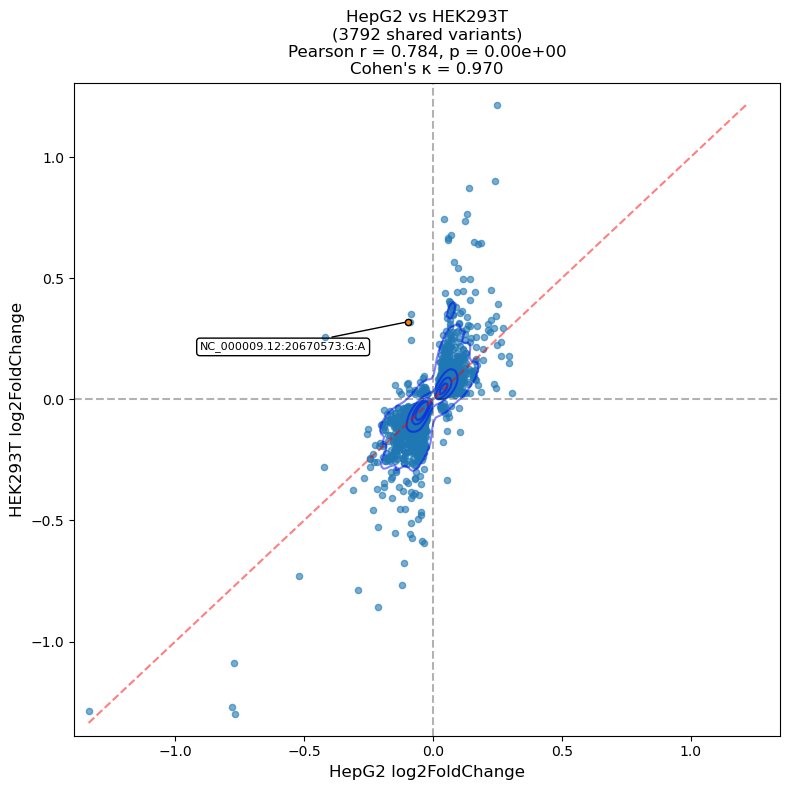

In [87]:
hepg2_log2fc_col = 'log2FC.HepG2'
hek293t_log2fc_col = 'log2FC.HEK293T'

sig_variants = merged_df[(merged_df['significant.HepG2']==True) & (merged_df['significant.HEK293T']==True)]

fig, ax = plt.subplots(figsize=(8, 8))

sns.kdeplot(data=sig_variants, x=hepg2_log2fc_col, y=hek293t_log2fc_col, ax=ax,
            levels=5, color='blue', alpha=0.5, linewidths=1.5)
min_val = min(sig_variants[hepg2_log2fc_col].min(), sig_variants[hek293t_log2fc_col].min())
max_val = max(sig_variants[hepg2_log2fc_col].max(), sig_variants[hek293t_log2fc_col].max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.5)

ax.scatter(sig_variants[hepg2_log2fc_col], sig_variants[hek293t_log2fc_col], alpha=0.6, s=20)
ax.set_xlabel('HepG2 log2FoldChange', fontsize=12)
ax.set_ylabel('HEK293T log2FoldChange', fontsize=12)

corr, pval = pearsonr(sig_variants[hepg2_log2fc_col], sig_variants[hek293t_log2fc_col])
cat1 = np.sign(sig_variants[hepg2_log2fc_col])
cat2 = np.sign(sig_variants[hek293t_log2fc_col])
kappa = cohen_kappa_score(cat1, cat2)
ax.set_title(f'HepG2 vs HEK293T\n({len(sig_variants)} shared variants)\nPearson r = {corr:.3f}, p = {pval:.2e}\nCohen\'s κ = {kappa:.3f}', fontsize=12)

ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='black', linestyle='--', alpha=0.3)

# Highlight the specific variant
highlight_variants = ['variants/NC_000009.12:20670573:G:A']
highlight_data = sig_variants[sig_variants['variant'].isin(highlight_variants)]

if len(highlight_data) > 0:
    ax.scatter(highlight_data[hepg2_log2fc_col], highlight_data[hek293t_log2fc_col], 
               s=20, edgecolors='black', linewidths=1, zorder=5)
    
    # Add text labels with arrows for each highlighted variant
    for idx in highlight_data.index:
        variant_name = highlight_data.loc[idx, 'variant'].split('/')[1]
        x = highlight_data.loc[idx, hepg2_log2fc_col]
        y = highlight_data.loc[idx, hek293t_log2fc_col]
        
        ax.annotate(variant_name, xy=(x, y), xytext=(-150, -20), 
                   textcoords='offset points', fontsize=8,
                   bbox=dict(boxstyle='round,pad=0.3', edgecolor='black', facecolor='none'),
                   arrowprops=dict(arrowstyle='-', color='black', lw=1))

plt.tight_layout()
plt.show()

## Inspect TF binding effect predictions at discordant variant using SEMpl/SEMVAR

https://pubmed.ncbi.nlm.nih.gov/31373606/

https://data.igvf.org/software/semvar/

Variant effect scores are interpreted as the log2FC between binding scores of the alt and ref sequences overlapping the SNP effect matrix (SEM).

Annotations (binding_ablated, binding increased, etc.) are determined by comparing alt and ref scores to a randomized baseline binding score.


In [88]:
variant_url = "%s/api/variants/proteins?spdi=%s&verbose=false" % (api_host, 'NC_000009.12:20670573:G:A')
print(variant_url)
res = paginated(variant_url, 500, 1000)

https://catalog-api-dev.demo.igvf.org/api/variants/proteins?spdi=NC_000009.12:20670573:G:A&verbose=false


In [89]:
sempl_results = pd.DataFrame(res)
sempl_results.drop_duplicates(subset='motif', inplace=True)
sempl_results['log2refscore'] = np.log2(sempl_results['ref_score'])
sempl_results['log2altscore'] = np.log2(sempl_results['alt_score'])
sempl_results['TF_name'] = sempl_results['motif'].str.split('/').str[1].str.split('_').str[0]

In [90]:
sempl_results.head()

,sequence_variant,protein_complex,biosample_term,biological_context,class,label,name,method,files_filesets,source,...,is_complex,motif,variant_effect_score,SEMpl_annotation,SEMpl_baseline,alt_score,ref_score,log2refscore,log2altscore,TF_name
0,variants/NC_000009.12:20670573:G:A,complexes/CPX-1971,None,None,prediction,predicted allele-specific binding,modulates binding of,SEMVAR,files_filesets/IGVFFI7979KDIB,IGVF,...,True,motifs/E2F1:TFDP1_SEMpl,-0.882784,binding_ablated,-1.051355,0.262628,0.484267,-1.046124,-1.928908,E2F1:TFDP1
1,variants/NC_000009.12:20670573:G:A,complexes/CPX-7641,None,None,prediction,predicted allele-specific binding,modulates binding of,SEMVAR,files_filesets/IGVFFI0028UJBA,IGVF,...,True,motifs/E2F4:TFDP1_SEMpl,-0.882784,binding_ablated,-1.103261,0.262628,0.484267,-1.046124,-1.928908,E2F4:TFDP1
2,variants/NC_000009.12:20670573:G:A,proteins/ENSP00000242057,None,None,prediction,predicted allele-specific binding,modulates binding of,SEMVAR,files_filesets/IGVFFI4440LLKE,IGVF,...,False,motifs/AHR_SEMpl,-0.124088,binding_decreased,-0.671761,0.779353,0.849353,-0.235564,-0.359652,AHR
3,variants/NC_000009.12:20670573:G:A,proteins/ENSP00000262904,None,None,prediction,predicted allele-specific binding,modulates binding of,SEMVAR,files_filesets/IGVFFI6560OWUF,IGVF,...,False,motifs/E2F3_SEMpl,-1.244519,binding_ablated,-1.379388,0.185067,0.438498,-1.189359,-2.433878,E2F3
4,variants/NC_000009.12:20670573:G:A,proteins/ENSP00000262965,None,None,prediction,predicted allele-specific binding,modulates binding of,SEMVAR,files_filesets/IGVFFI3594NNNB,IGVF,...,False,motifs/TCF3_SEMpl,0.225608,binding_increased,-1.534761,0.585031,0.500339,-0.999022,-0.773414,TCF3


(-6.1774766, 0.5236485999999998, -3.76487265, 0.17927965000000093)

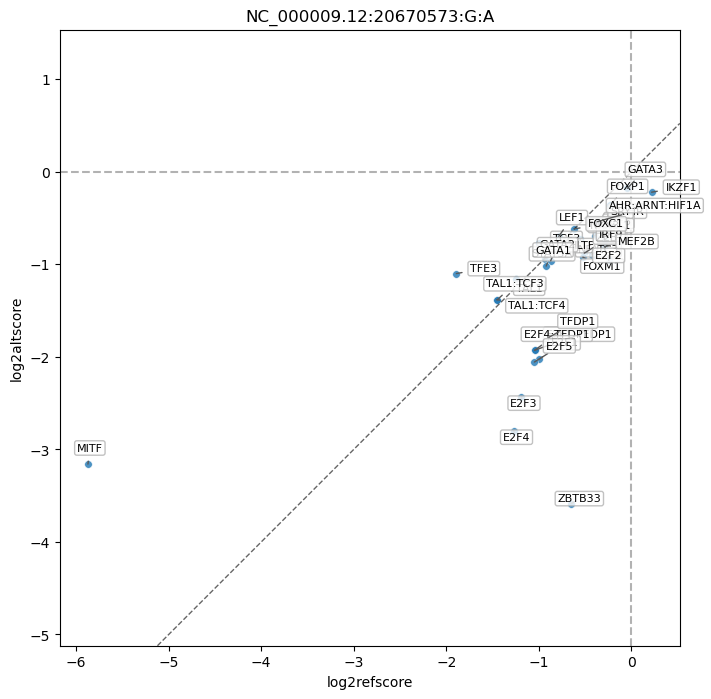

In [93]:
fig, ax = plt.subplots(figsize=(8, 8))

sns.scatterplot(
    data=sempl_results,
    x='log2refscore',
    y='log2altscore',
    ax=ax,
    s=30,
    alpha=0.8
)

offsets = [(8, 8), (-8, 8), (8, -8), (-8, -8), (10, 0), (-10, 0), (0, 10), (0, -10)]

for idx, row in sempl_results.iterrows():
    x = row['log2refscore']
    y = row['log2altscore']
    dx, dy = offsets[idx % len(offsets)]

    ax.annotate(
        row['TF_name'],
        xy=(x, y),
        xytext=(dx, dy),
        textcoords='offset points',
        fontsize=8,
        ha='left',
        va='bottom',
        bbox=dict(
            boxstyle='round,pad=0.2',
            facecolor='white',
            edgecolor='0.7',
            alpha=0.8
        ),
        arrowprops=dict(
            arrowstyle='-',
            color='0.35',
            lw=1,
            shrinkA=4,
            shrinkB=0,
            connectionstyle='arc3,rad=0.0'
        )
    )
plt.title('NC_000009.12:20670573:G:A')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='black', linestyle='--', alpha=0.3)
ax.axline((0, 0), slope=1, color='black', linestyle='--', alpha=0.6, linewidth=1)
plt.axis('equal')

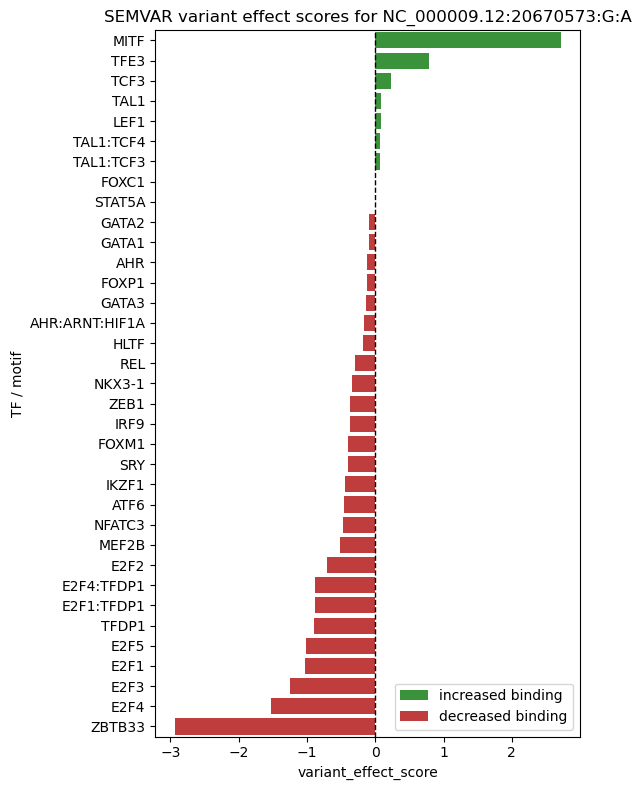

In [95]:
plot_df = sempl_results.sort_values("variant_effect_score", ascending=False).copy()
plot_df["direction"] = np.where(
    plot_df["variant_effect_score"] >= 0, "increased binding", "decreased binding"
)

fig, ax = plt.subplots(figsize=(6, 8))
sns.barplot(
    data=plot_df,
    y="TF_name",
    x="variant_effect_score",
    hue="direction",
    dodge=False,
    palette={"increased binding": "#2ca02c", "decreased binding": "#d62728"},
    ax=ax
)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("variant_effect_score")
ax.set_ylabel("TF / motif")
ax.set_title(f"SEMVAR variant effect scores for {variant_name}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()